In [5]:
from typing import TypedDict, Annotated
from operator import add
from langgraph.constants import START, END
from langgraph.graph import StateGraph
from datetime import datetime
from IPython.display import Image, display
from time import sleep
class CustomState(TypedDict):
    nodes: Annotated[list[str], add]

def node1(state: CustomState):
    print(f"Node1执，state: {state}, 时间: {datetime.now()}")
    return {"nodes": ["Node1"]}

def node2(state: CustomState):
    sleep(1)
    print(f"Node2，state: {state}, 时间: {datetime.now()}")
    return {"nodes": ["Node2"]}

def node3(state: CustomState):
    print(f"Node3，state: {state}, 时间: {datetime.now()}")
    return {"nodes": ["Node3"]}

def node4(state: CustomState):
    print(f"Node4，state: {state}, 时间: {datetime.now()}")
    return {"nodes": ["Node4"]}

graph_builder = StateGraph(CustomState)

graph_builder.add_node("Node1", node1)
graph_builder.add_node("Node2", node2)
graph_builder.add_node("Node3", node3)
graph_builder.add_node("Node4", node4)
graph_builder.add_edge(START, "Node1")
graph_builder.add_edge("Node1", "Node2")
graph_builder.add_edge("Node1", "Node3")
graph_builder.add_edge("Node2", "Node4")
graph_builder.add_edge("Node3", "Node4")
graph_builder.add_edge("Node4", END)

graph = graph_builder.compile()

# 执行graph
result = graph.invoke({"nodes": []})
print(result)

Node1执，state: {'nodes': []}, 时间: 2026-11-26 14:06:48.924967
Node3，state: {'nodes': ['Node1']}, 时间: 2026-11-26 14:06:48.928663
Node2，state: {'nodes': ['Node1']}, 时间: 2026-11-26 14:06:49.929467
Node4，state: {'nodes': ['Node1', 'Node2', 'Node3']}, 时间: 2026-11-26 14:06:49.932550
{'nodes': ['Node1', 'Node2', 'Node3', 'Node4']}


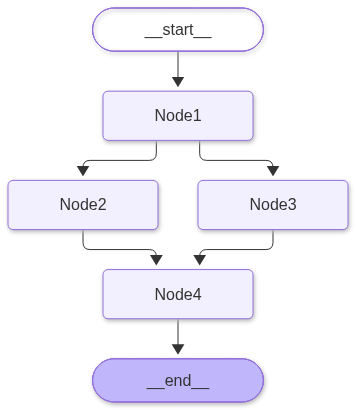

In [6]:
display(Image(graph.get_graph().draw_mermaid_png()))